# GMM candidate diagnostics after confirmation CV

In [9]:
from pathlib import Path
from dataclasses import replace
from itertools import combinations
import sys

possible_roots = [
    Path.cwd().resolve()
    ,Path.cwd().resolve().parent
    ,Path.cwd().resolve() / "Project_2_UnsupervisedLearning"
]
ROOT = next(
    (path for path in possible_roots if (path / "src/config.py").is_file())
    ,None
)
if ROOT is None:
    raise FileNotFoundError("Open from the workspace, project root or notebooks folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score

from src.config import ProjectConfig
from src.data import balanced_sample, load_development_data, CORE
from src.io_utils import read_json, write_json
from src.modeling import cluster_metrics
from src.modeling import (
    fit_candidates
    ,predict_states
    ,describe_assignments
    ,assignment_stability
    ,refit_recorded_fold
    ,covariance_diagnostics
    ,likelihood_tail_diagnostics
    ,feature_shift_report
    ,compare_validation_coverage
    ,run_remedy_cv
    ,save_candidate_bundle
    ,plot_candidate_diagnostics
)

OUT = ROOT / "output" / "03_gmm_grid_search"
DIAG_OUT = OUT / "candidate_diagnostics"
DIAG_OUT.mkdir(
    parents=True
    ,exist_ok=True
)
confirmation_settings = read_json(OUT / "confirmation/settings.json")
cfg = replace(
    ProjectConfig()
    ,random_seed=int(confirmation_settings["sampling_seed"])
)
development_rows, data_audit = load_development_data(ROOT, cfg)
feature_sets = read_json(
    ROOT / "output/02_time_split_and_preprocessing/feature_sets.json"
)
confirmation_cv = pd.read_csv(OUT / "confirmation/gmm_cv.csv")
confirmation_summary = pd.read_csv(OUT / "confirmation/summary.csv")
write_json(DIAG_OUT / "data_audit.json", data_audit)

print("Development dates:", development_rows.Date.min(), development_rows.Date.max())
assert development_rows.Date.max() < pd.Timestamp(cfg.test_start)

Development dates: 2017-03-31 00:00:00 2020-12-30 00:00:00


## 1. Select three candidate models for further evaluation

Based on the confirmation CV results, we carry forward three models:
- Set A: 6 components with full covariance.
- Set C: 10 components with full covariance.
- Set D: 10 components with full covariance.

These models are promising candidates, but we need to examine their cluster assignments before deciding which feature set is most suitable.

We set the fitting options directly so that the results do not depend on whether the configuration uses the quick or full profile. Each model uses the same sample of up to 200000 training observations from 2017–2019, with two initializations and a fixed model seed of 24. Using these settings makes the fitting procedure consistent and reproducible.

We then apply all three models to the same 50000 stock-date observations from 2020. This gives us a common set of observations for examining cluster sizes, feature profiles, membership uncertainty, and agreement between assignments. Raw log-likelihood values still cannot directly rank the different feature sets.

At this stage, we are keeping these models for closer inspection rather than selecting a final winner. The next checks will help determine whether their clusters are stable, sufficiently populated, and meaningfully different. The 2020 observations remain part of development analysis; the 2021 test data is not used.

In [2]:
provisional_specifications = [
    {"feature_set": "A", "k": 6, "covariance": "full"}
    ,{"feature_set": "C", "k": 10, "covariance": "full"}
    ,{"feature_set": "D", "k": 10, "covariance": "full"}
]

reference_fit_options = {
    "train_cap": int(confirmation_settings["options"]["train_cap"])
    ,"n_init": int(confirmation_settings["options"]["n_init"])
    ,"max_iter": int(confirmation_settings["options"]["max_iter"])
    ,"reg_covar": 1e-5
    ,"tol": 1e-3
    ,"init_params": "kmeans"
}

training_rows = development_rows.loc[
    development_rows.Date.le(pd.Timestamp(cfg.train_end))
]
anchor_rows = balanced_sample(
    development_rows.loc[
        development_rows.Date.between(cfg.valid_start, cfg.valid_end)
    ]
    ,cap=50000
    ,random_seed=cfg.random_seed + 22
)
assert training_rows.Date.max() < anchor_rows.Date.min()

pd.Series(anchor_rows.index, name="RowKey").to_csv(
    DIAG_OUT / "anchor_row_keys.csv"
    ,index=False
)

reference_artifacts = fit_candidates(
    training_rows
    ,feature_sets
    ,None
    ,cfg
    ,specifications=provisional_specifications
    ,fit_options=reference_fit_options
    ,model_seed=24
    ,compute_metrics=False
    ,require_convergence=False
)[0]

reference_scores = {}
reference_profiles = {}

for candidate_id, artifact in reference_artifacts.items():
    scores = predict_states(
        artifact
        ,anchor_rows
        ,cfg
        ,include_diagnostics=True
    )
    profiles = describe_assignments(
        artifact, anchor_rows, scores, cfg
    )
    reference_scores[candidate_id] = scores
    reference_profiles[candidate_id] = profiles

    print(candidate_id, "| converged:", artifact["converged"])
    display(profiles["sizes"])
    display(profiles["uncertainty"])
    display(profiles["raw_feature_medians"].T)

    scores.to_csv(DIAG_OUT / f"{candidate_id}_anchor_assignments.csv")
    for table_name, table in profiles.items():
        table.to_csv(DIAG_OUT / f"{candidate_id}_{table_name}.csv")

A_k6_full | converged: True


,count,share,fitted_mixture_weight
State,,,
0,22907,0.45814,0.571267
1,9594,0.19188,0.241710
2,4238,0.08476,0.055591
3,5335,0.10670,0.035164
4,2316,0.04632,0.054965
5,5610,0.11220,0.041303


,count,mean_max_probability,mean_normalized_entropy,share_probability_below_06
State,,,,
0,22907,0.990038,0.013627,0.005850
1,9594,0.975587,0.032060,0.014592
2,4238,0.994632,0.007460,0.002360
3,5335,0.993694,0.007981,0.003374
4,2316,0.995650,0.005646,0.003886
5,5610,0.977962,0.028730,0.015865


State,0,1,2,3,4,5
OpenToCloseReturn,-0.001344,-0.001002,-0.000939,0.000000e+00,-0.001123,0.003113
HighLowRange,0.023350,0.024585,0.024271,3.377386e-02,0.021702,0.062362
GapReturn,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
LogReturn1Day,-0.000555,-0.000471,0.000000,0.000000e+00,-0.000949,0.003799
Momentum5Days,-0.001040,-0.001312,-0.001213,7.285839e-17,-0.004498,0.008292
Momentum20Days,0.002401,0.002853,0.001709,-1.088139e-03,-0.008980,0.008052
Momentum60Days,0.016185,0.019344,-0.002748,-2.328590e-02,0.001070,-0.094460
Volatility20Days,0.019542,0.021252,0.021290,2.818659e-02,0.018744,0.043153
Volatility60Days,0.021280,0.023601,0.023452,2.907967e-02,0.019788,0.038355
VolatilityRatio20To60,0.945681,0.921487,0.923500,9.817101e-01,0.944706,1.211088


C_k10_full | converged: True


,count,share,fitted_mixture_weight
State,,,
0,8208,0.16416,0.131047
1,3003,0.06006,0.132907
2,4044,0.08088,0.020733
3,3488,0.06976,0.080743
4,6163,0.12326,0.205938
5,3831,0.07662,0.046106
6,2356,0.04712,0.038879
7,6276,0.12552,0.137345
8,1848,0.03696,0.114312


... (2 outputs left out)

D_k10_full | converged: True


,count,share,fitted_mixture_weight
State,,,
0,4829,0.09658,0.095449
1,4541,0.09082,0.078104
2,5044,0.10088,0.129288
3,5420,0.10840,0.101762
4,3447,0.06894,0.145610
5,5920,0.11840,0.088751
6,3496,0.06992,0.139240
7,6720,0.13440,0.046839
8,9104,0.18208,0.080010


,count,mean_max_probability,mean_normalized_entropy,share_probability_below_06
State,,,,
0,4829,0.905386,0.100368,0.065438
1,4541,0.920820,0.083084,0.053512
2,5044,0.887351,0.122474,0.080888
3,5420,0.895128,0.116537,0.071587
4,3447,0.901994,0.106189,0.073397
5,5920,0.902184,0.105342,0.074662
6,3496,0.887216,0.124973,0.081236
7,6720,0.941059,0.059539,0.043452
8,9104,0.923260,0.081431,0.050198


State,0,1,2,3,4,5,6,7,8,9
LogReturn1Day,-0.002503,0.000000,-0.001024,-0.000488,-0.001559,-0.002185,0.000000,0.004297,0.000000,0.000000e+00
Momentum5Days,-0.016109,0.002654,-0.005349,-0.002101,-0.007065,-0.005157,-0.001229,0.020873,0.006540,-3.122502e-17
Momentum20Days,-0.044059,0.017131,-0.009348,-0.002226,-0.014981,0.003559,-0.007431,0.017749,0.038810,-1.327434e-03
Volatility20Days,0.027385,0.016162,0.017936,0.018703,0.014242,0.027309,0.012214,0.047354,0.028345,8.301213e-03
Volatility60Days,0.020338,0.026184,0.017521,0.021648,0.012981,0.025637,0.015286,0.041710,0.034942,9.383071e-03
VolatilityRatio20To60,1.369363,0.614466,1.020535,0.851651,1.114464,1.105582,0.778767,1.265379,0.820244,9.016053e-01
CloseToMovingAverage20Days,-0.019532,0.006357,-0.006523,-0.002186,-0.009694,-0.002370,-0.002996,0.022406,0.014961,-3.066544e-04
VolumeVs20Days,0.060165,0.018782,0.084870,0.037461,0.118633,0.026735,0.073619,0.011838,-0.069730,1.094701e-01


Columns:
- `count` describe how many observations were assigned into each state
- `share`: what proportion of the anchor sample (2020) belongs to this state
- `fitted_mixture_weight`: how common was this component in the fitted training distribution.
- `mean_max_probability`: how strongly does the model prefer the assigned state or the average probability given to their assigned component within each state.
- `mean_normalized_entropy`: how widely is membership spread across all components? Ranges from zero to one with 0 means entirely concentrated in one component and 1 means equally divided across all components.
- `share_probability_below_06`: how often are assignments relatively ambiguous? This column counts observations whose winning probability is below 0.6, then divide by the number assigned to the state. 
- `Median scaled features` Does this state usually have higher volatility, stronger momentum, or lower trading activity than the training data (mean)? They help describe each state by showing how far its typical anchor feature values (median) are above or below the corresponding training means, measured in training standard deviations.

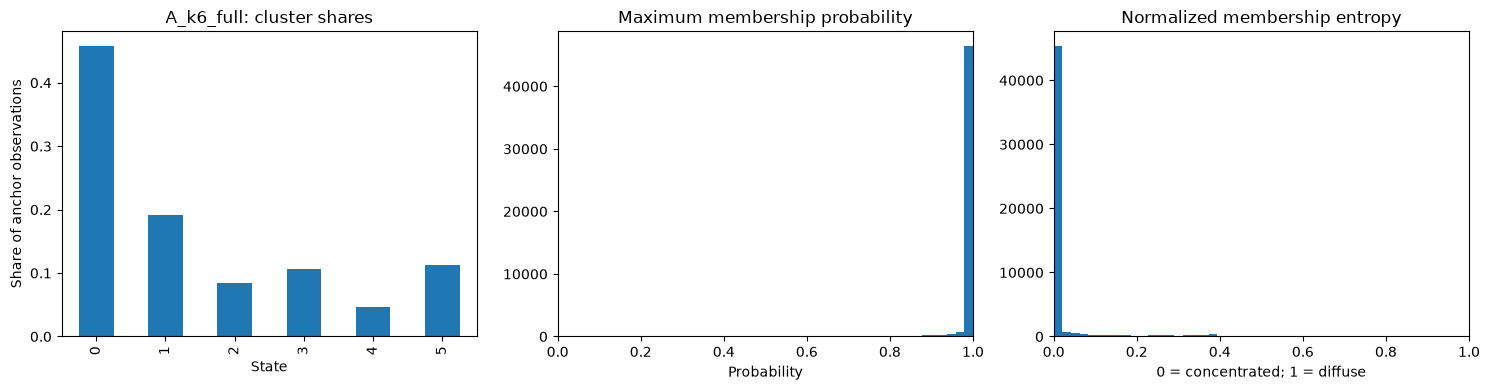

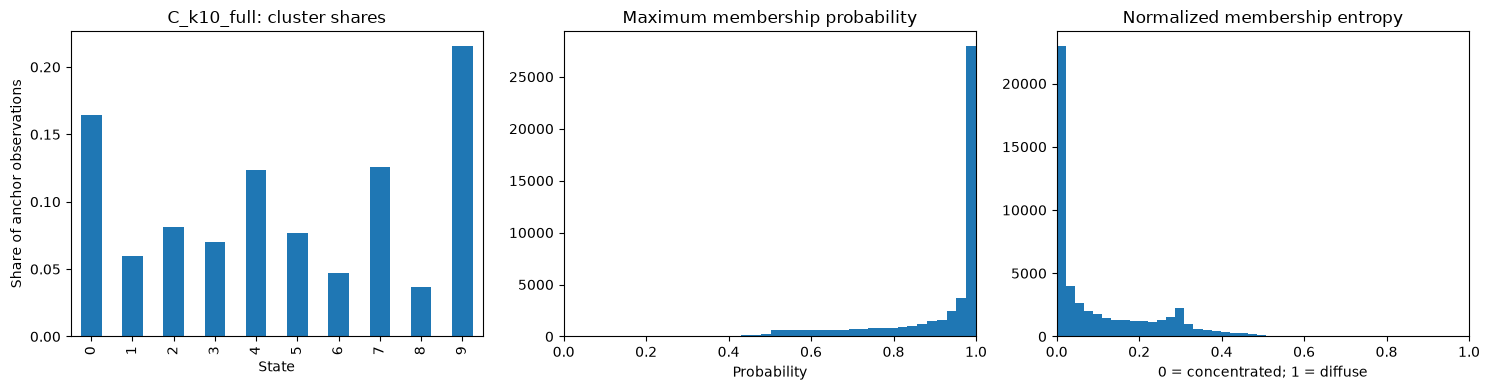

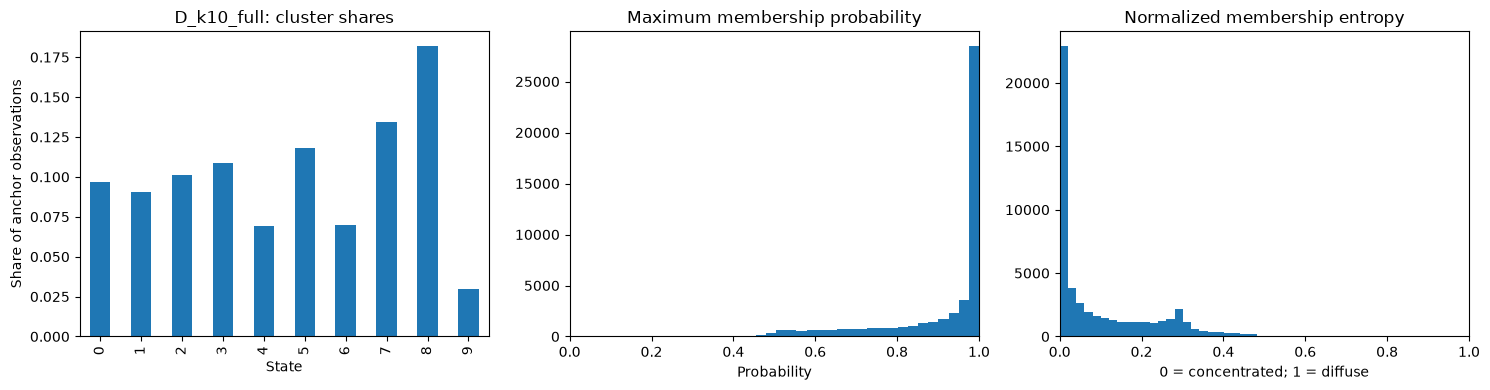

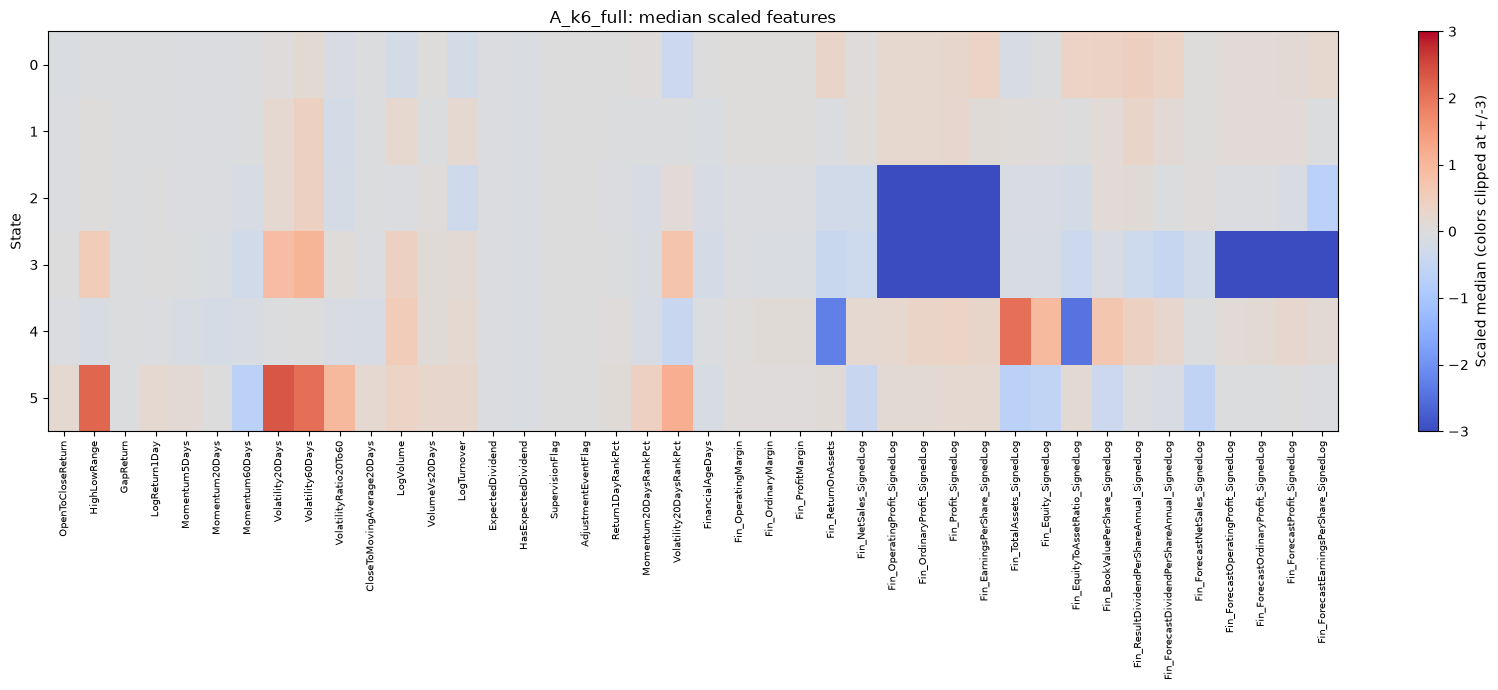

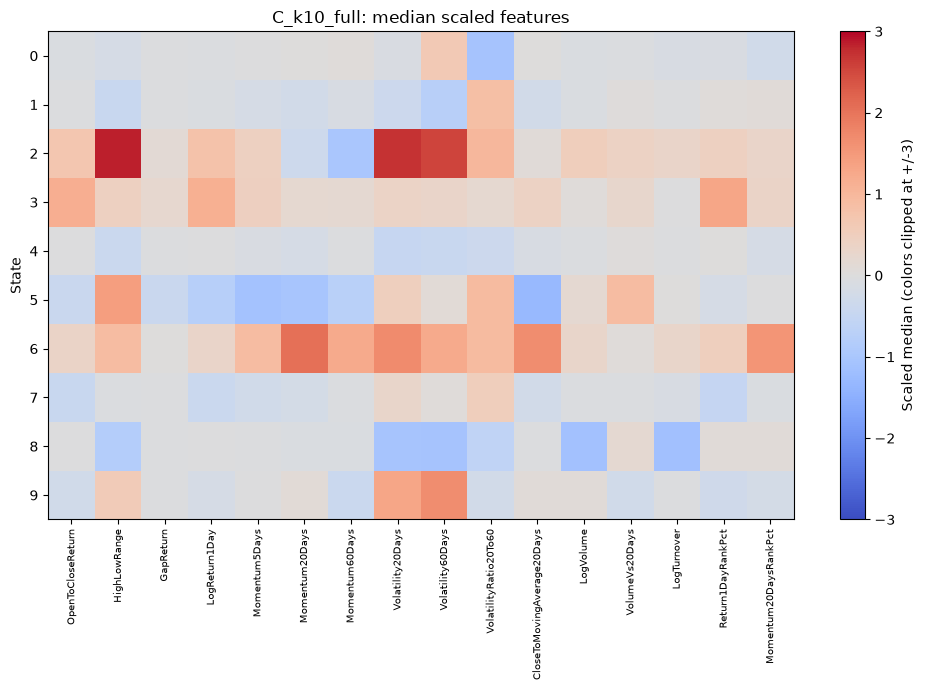

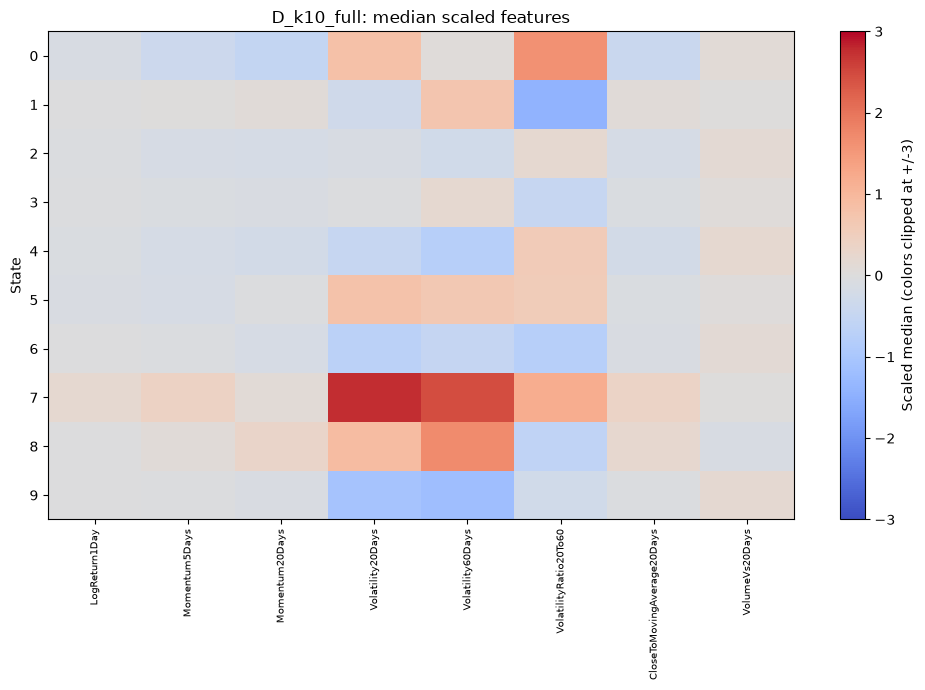

In [3]:
# Cluster shares and membership uncertainty on the common development anchor.
for candidate_id, scores in reference_scores.items():
    sizes = reference_profiles[candidate_id]["sizes"]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sizes["share"].plot.bar(
        ax=axes[0]
        ,title=f"{candidate_id}: cluster shares"
    )
    axes[0].set_ylabel("Share of anchor observations")

    axes[1].hist(scores["StateProbability"], bins=30)
    axes[1].set_title("Maximum membership probability")
    axes[1].set_xlabel("Probability")
    axes[1].set_xlim(0, 1)

    axes[2].hist(scores["normalized_entropy"], bins=30)
    axes[2].set_title("Normalized membership entropy")
    axes[2].set_xlabel("0 = concentrated; 1 = diffuse")
    axes[2].set_xlim(0, 1)

    fig.tight_layout()
    fig.savefig(
        DIAG_OUT / f"{candidate_id}_sizes_uncertainty.png"
        ,dpi=150
        ,bbox_inches="tight"
    )
    plt.show()

# Feature profiles in units of the training-fitted standard deviation.
for candidate_id, profiles in reference_profiles.items():
    medians = profiles["scaled_feature_medians"]
    fig, ax = plt.subplots(
        figsize=(max(10, 0.4 * len(medians.columns)), 7)
    )
    image = ax.imshow(
        medians.to_numpy()
        ,aspect="auto"
        ,cmap="coolwarm"
        ,vmin=-3
        ,vmax=3
    )
    ax.set_xticks(
        range(len(medians.columns))
        ,labels=medians.columns
        ,rotation=90
        ,fontsize=7
    )
    ax.set_yticks(range(len(medians.index)), labels=medians.index)
    ax.set_ylabel("State")
    ax.set_title(f"{candidate_id}: median scaled features")
    fig.colorbar(image, ax=ax, label="Scaled median (colors clipped at +/-3)")
    fig.tight_layout()
    fig.savefig(
        DIAG_OUT / f"{candidate_id}_feature_profiles.png"
        ,dpi=150
        ,bbox_inches="tight"
    )
    plt.show()

### Interpretation from plots
For set A, the model has very confident assignments, with substantial financial structure. A's states range from 4.63% to 45.81% of the anchor sample. None is empty or represented only a handful of observations. State 0 and 1 together contain approximately 65% of the sample. The assignments are exceptionally concentrated as seen in `mean_max_probability` and `mean_normalized_entropy` plots. Across the anchor sample, mean winning membership probability is about 98.69%, mean normalized entropy 0.017 and observations with winning probability below 0.6 is 0.8%. This means the model usually strongly prefers one component over the alternatives. Their market-feature medians are fairly similar. As seen in the table of raw_feature_medians, state 0 with the largest share 45.81%, the assigned observations have moderate volatility (lower than state 3 and 5) and positive profitability (OperatingMargin and ProfitMargin). State 1 has similar market behavior to State 0, with higher absolute trading activity (LogVolume and LogTurnover) and slightly lower profitability. State 2 has negative current profitability, with positive forecast-profit measures (Fin_ForecastOperatingProfit_SignedLog, Fin_ForecastProfit_SignedLog, and Fin_ForecastEarningsPerShare_SignedLog). State 3 has more negative profitability and forecasts, with higher volatility than States 0–2. State 4 has a much larger asset base, a different balance-sheet profile, and relatively low volatility. State 5 has the highest volatility and intraday range (HighLowRange), with a rebound-like momentum profile (Momentum5Days and Momentum20Days are positive while Momentum60Days is negative).

Set C have several substantial groups with more ambiguous boundaries. C distributes observations across ten states more evenly than A. The probability histogram still has a strong peak near one, but its tail extends much farther toward lower probabilities than A’s. The entropy distribution also has a broader spread. Mean maximum membership probability is 90.85%. Observations with probability at least 0.95 is 63.82%. Observations with probability below 0.6	is 6.84%. Mean normalized entropy is 0.099 so approximately 3422 observations have a winning probability below 0.6. This means that C makes many decisive assignments but also encounters a meaningful group of observations near component boundaries. That is plausible for market-behaviour features. Momentum, volatility, and trading activity vary continuously. An observation may be transitioning from a declining state to a recovery state, for example, without fitting neatly into either component.

Set D has similar uncertainty to C using a smaller feature set. Compared with A, the assigned population is less dominated by a single component. Compared with C, its largest component is somewhat smaller, although it also has a smaller least-populated state. D has slightly more concentrated assignments, but the differences are small. The more interesting result is that D achieves a broadly similar membership-uncertainty pattern using 8 features, compared with C’s 16.

C and D have a small entropy bump around 0.3. For a ten-component model, an observation divided equally between two components has probabilities approximately [0.5, 0.5, 0, 0, 0, 0, 0, 0, 0, 0] = Its normalized entropy is 2 * 0.5*log(0.5) / log(10) = 0.301. The bump could therefore reflect observations whose membership is mainly split between two competing states. 

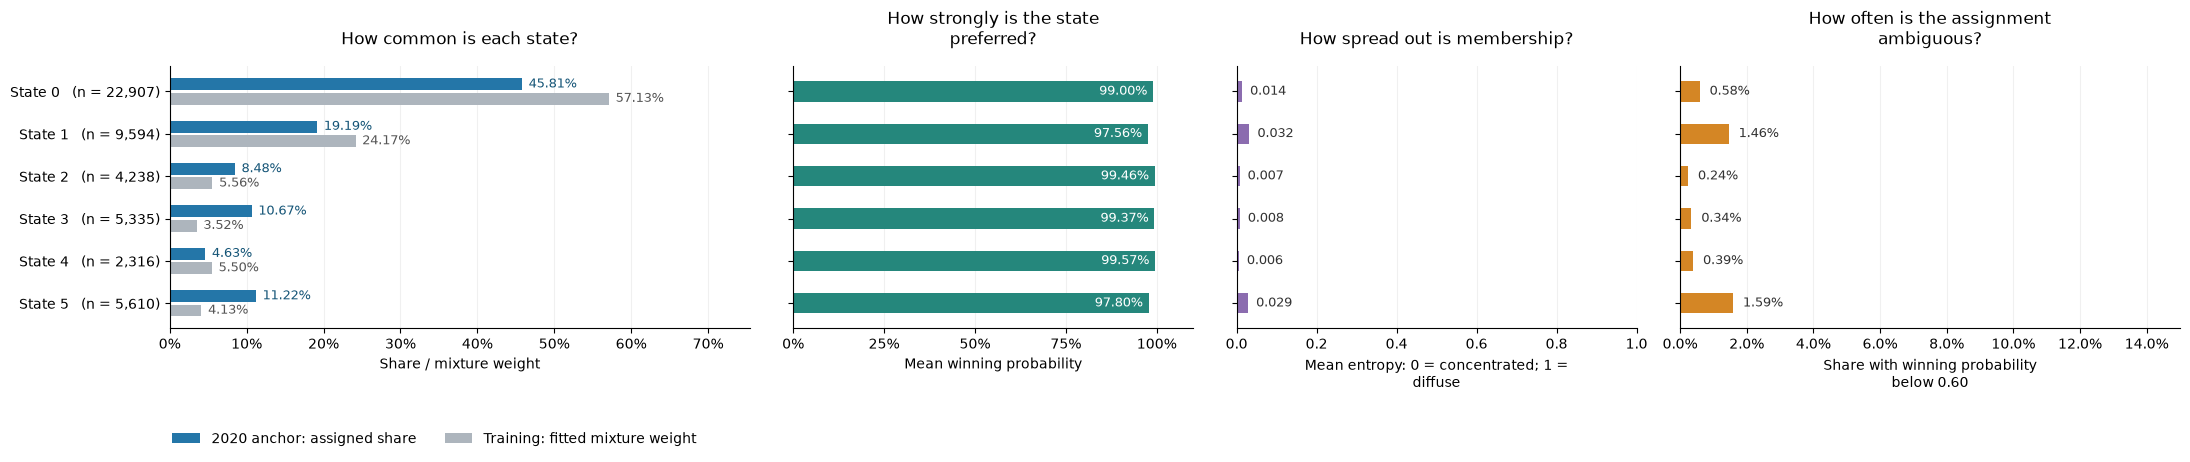

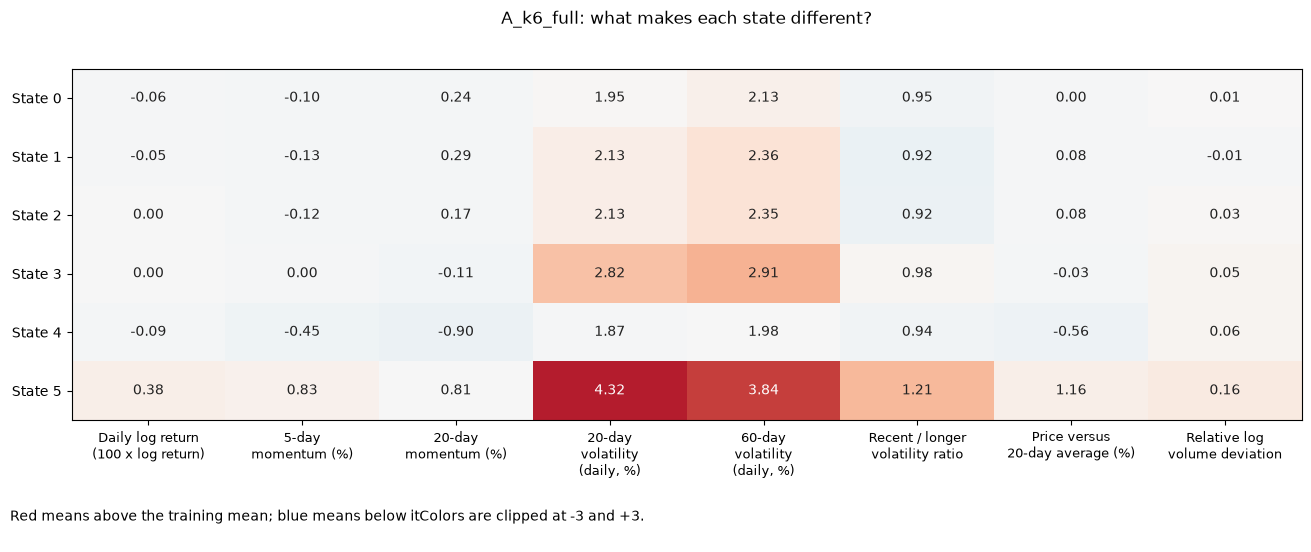

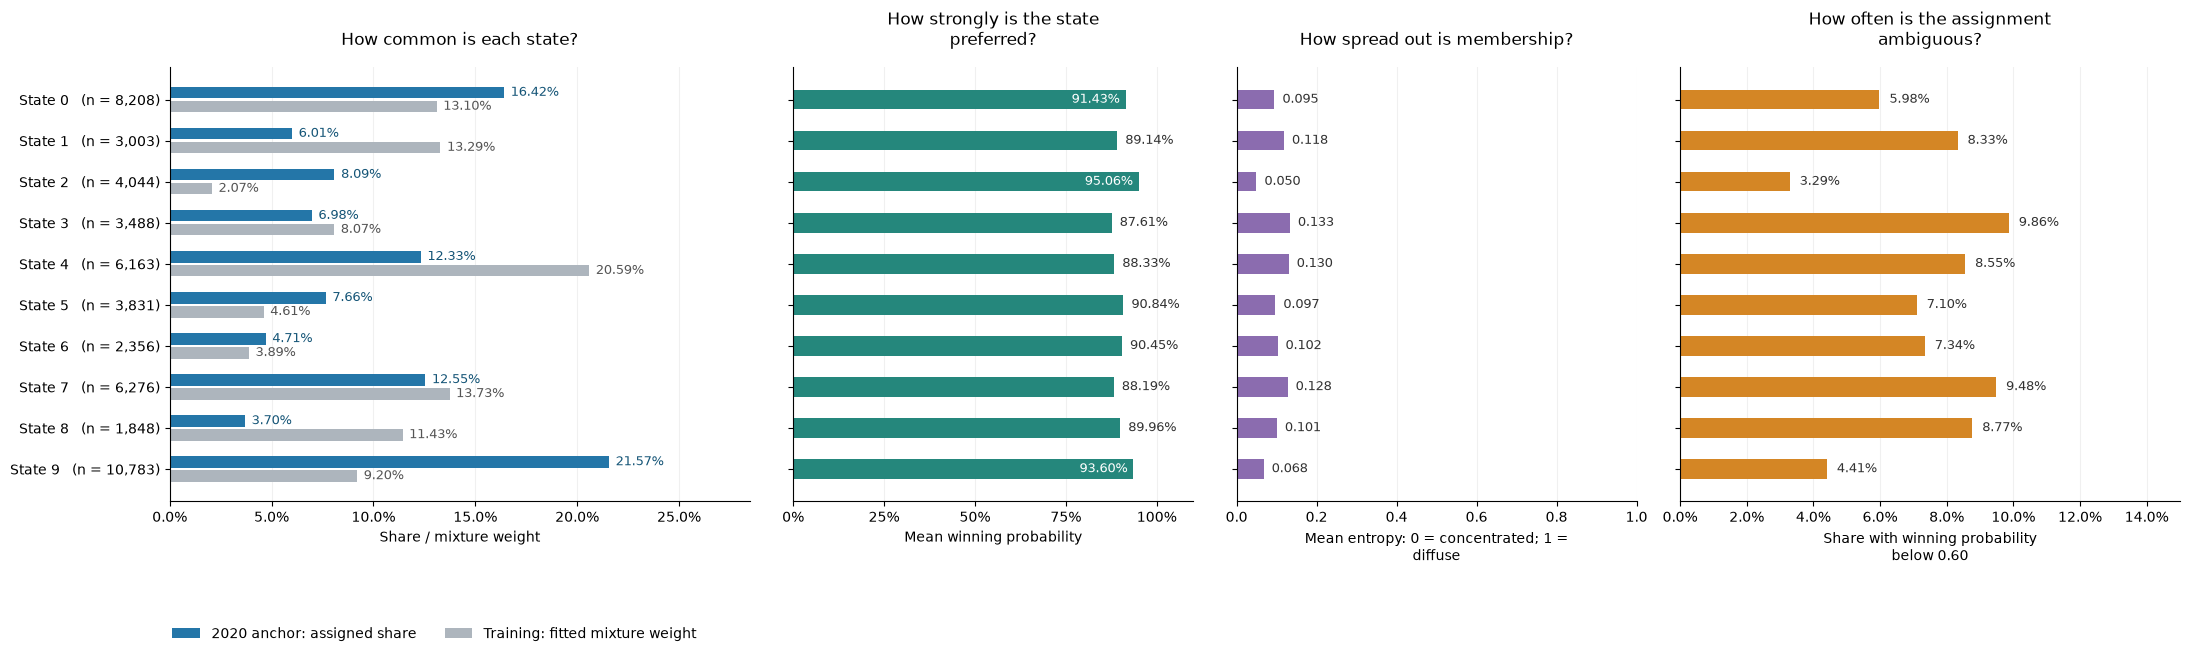

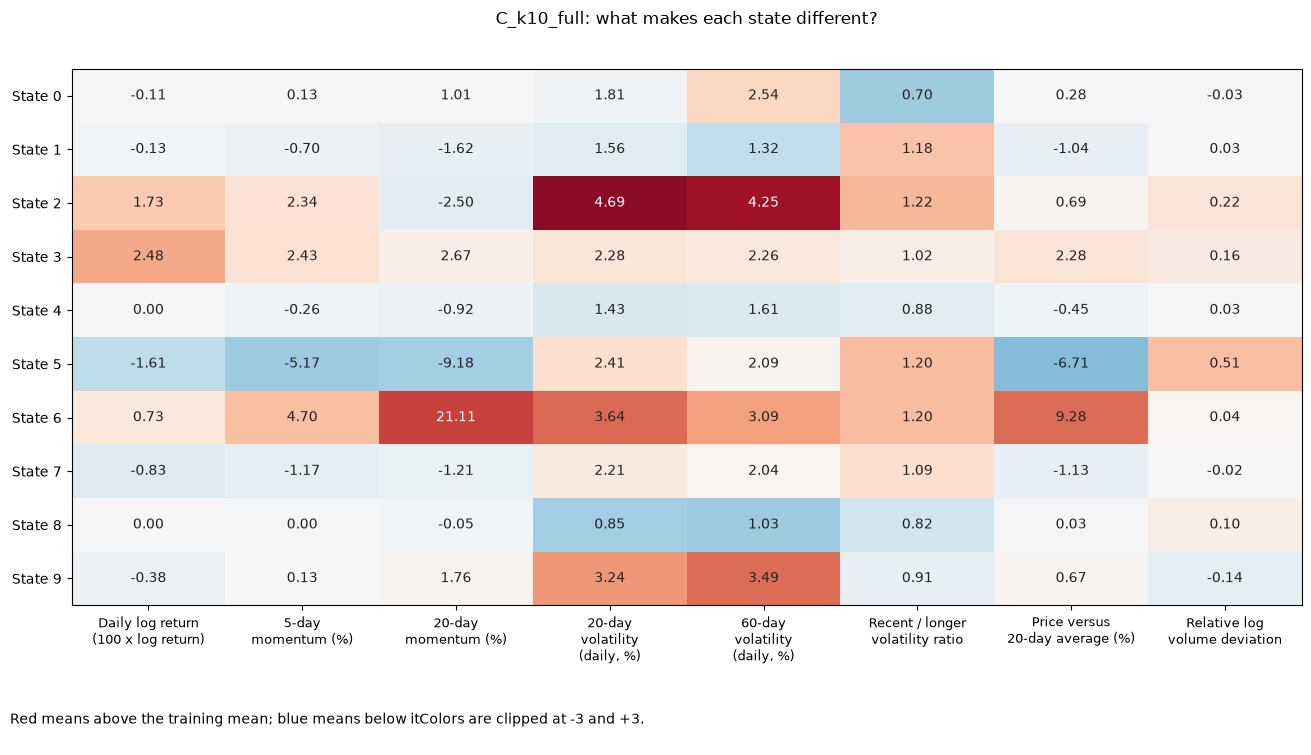

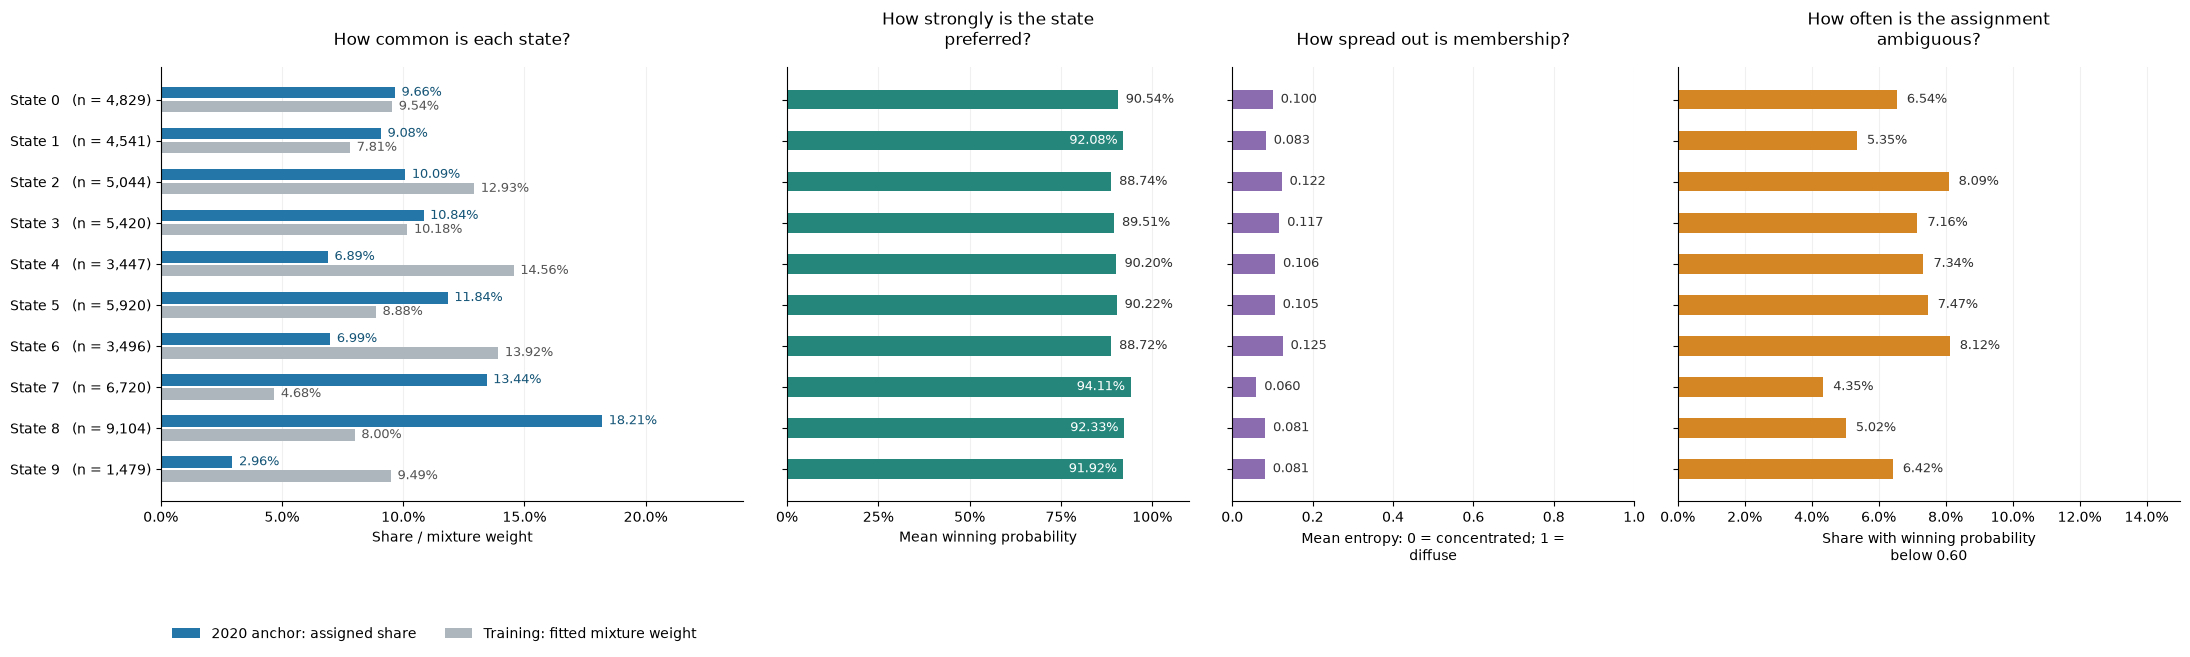

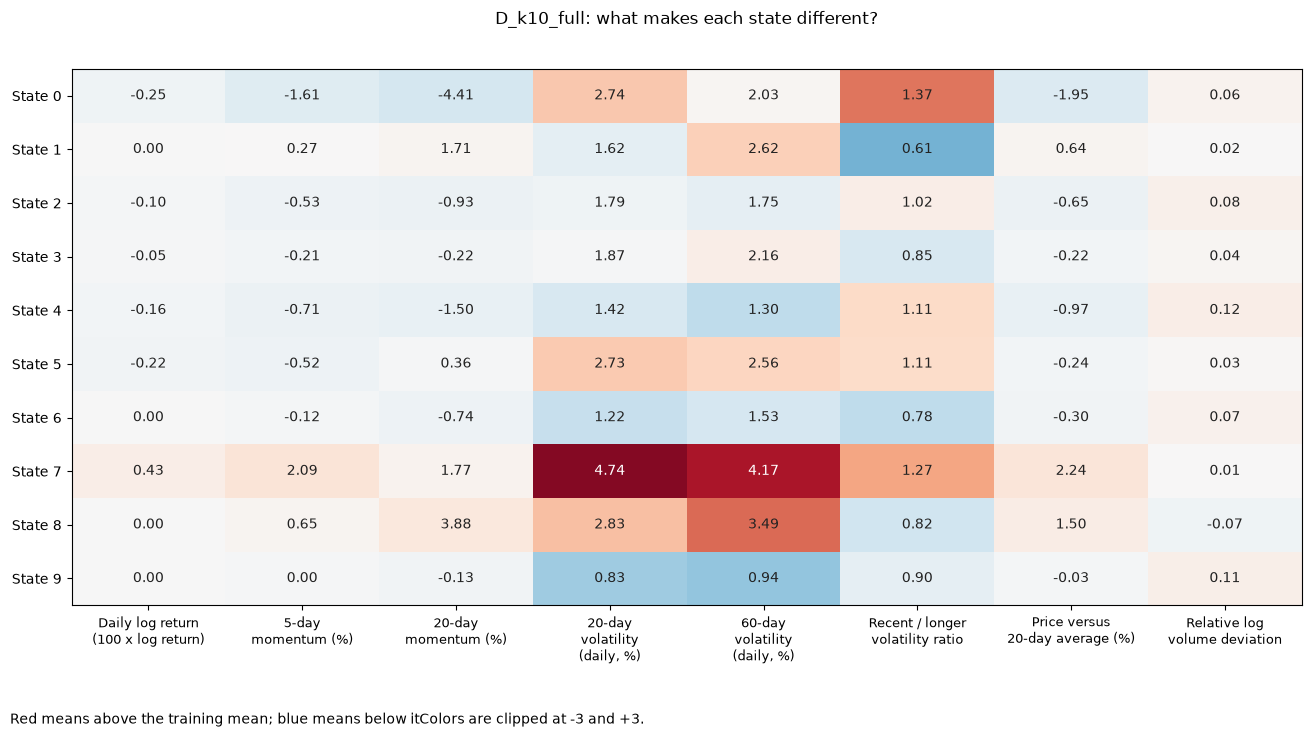

In [11]:


for candidate_id, profiles in reference_profiles.items():
    figures = plot_candidate_diagnostics(
        candidate_id
        ,profiles
        ,feature_names=CORE
        ,output_directory=DIAG_OUT / "interpretable_figures"
        ,anchor_label="2020 anchor"
        ,ambiguous_share_limit=15
    )

    display(figures["state_dashboard"])
    display(figures["feature_profiles"])
    plt.close(figures["state_dashboard"])
    plt.close(figures["feature_profiles"])


## Investigation of Set B

In [ ]:
b_artifact, b_training_sample, b_validation_rows = refit_recorded_fold(
    development_rows
    ,feature_sets
    ,cfg
    ,reference_fit_options
    ,feature_set="B"
    ,k=5
    ,fold_name="validate_2018"
    ,model_seed=24
    ,sampling_seed=int(confirmation_settings["sampling_seed"])
)

b_scores = predict_states(
    b_artifact
    ,b_validation_rows
    ,cfg
    ,batch_size=20000
    ,include_diagnostics=True
)

saved_match = confirmation_cv.loc[
    confirmation_cv["feature_set"].eq("B")
    & confirmation_cv["k"].eq(5)
    & confirmation_cv["covariance"].eq("full")
    & confirmation_cv["fold"].eq("validate_2018")
    & confirmation_cv["seed"].eq(24)
]
if len(saved_match) != 1:
    raise ValueError("Expected exactly one saved reference result.")

saved_ll = float(saved_match.iloc[0]["valid_log_likelihood"])
refitted_ll = b_scores["log_likelihood"].mean()

print("Saved confirmation LL:", saved_ll)
print("Refitted validation LL:", refitted_ll)
print("Difference:", refitted_ll - saved_ll)
print("Converged:", b_artifact["converged"])
print("Matches within tolerance:", np.isclose(saved_ll, refitted_ll, atol=1e-6, rtol=1e-6))

b_tail = likelihood_tail_diagnostics(
    b_artifact
    ,b_validation_rows
    ,b_scores
    ,tail_fraction=0.001
    ,worst_count=30
)
b_covariance = covariance_diagnostics(b_artifact)
b_feature_shifts = feature_shift_report(
    b_artifact
    ,b_training_sample
    ,b_validation_rows
)

display(b_tail["quantiles"])
display(b_tail["tail_summary"])
display(b_covariance)
display(b_feature_shifts)
display(b_tail["worst_rows"].head(10).T)

b_scores.to_csv(DIAG_OUT / "B_2018_all_validation_scores.csv")
b_tail["quantiles"].to_csv(DIAG_OUT / "B_2018_likelihood_quantiles.csv")
b_tail["tail_summary"].to_csv(DIAG_OUT / "B_2018_tail_contribution.csv")
b_tail["worst_rows"].to_csv(DIAG_OUT / "B_2018_worst_rows.csv")
b_covariance.to_csv(DIAG_OUT / "B_2018_covariance_diagnostics.csv", index=False)
b_feature_shifts.to_csv(DIAG_OUT / "B_2018_feature_shifts.csv")

Saved confirmation LL: -112.79631797560243
Refitted validation LL: -112.79631797560245
Difference: -1.4210854715202004e-14
Converged: True
Matches within tolerance: True


,log_likelihood
0.0000,-5.493108e+07
0.0001,-4.504392e+02
0.0010,-1.090801e+02
0.0100,-5.594454e+01
0.5000,8.150979e+00
0.9900,2.980913e+01
1.0000,3.422583e+01


,count,mean_ll,sum_ll,contribution_to_full_mean
in_worst_tail,,,,
False,464111,5.767305,2.676669e+06,5.761532
True,465,-118449.745592,-5.507913e+07,-118.557850


,State,weight,minimum_eigenvalue,maximum_eigenvalue,condition_number
0,0,0.038862,0.00001,34.651358,3.465136e+06
1,1,0.078192,0.00001,24.558465,2.455847e+06
2,2,0.013903,0.00001,73.473206,7.347321e+06
3,3,0.577168,0.00001,3.627091,3.627091e+05
4,4,0.291875,0.00001,6.660592,6.660592e+05


,training_missing_share,validation_missing_share,training_minimum,training_maximum,validation_minimum,validation_maximum,validation_abs_scaled_q99,validation_abs_scaled_max,validation_share_abs_scaled_over_10
ExpectedDividend,0.000000,0.000000,0.000000,279.000000,0.000000,390.000000,0.046970,184.613645,0.002919
Fin_OperatingMargin,0.031390,0.030040,-66.555556,3.844355,-86.962963,2.369737,0.484413,74.431354,0.000773
Fin_ProfitMargin,0.000830,0.000917,-44.777778,4.440476,-65.777778,9.281248,0.462424,63.685427,0.001065
SupervisionFlag,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.019625,50.954907,0.000024
AdjustmentEventFlag,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.027305,36.623515,0.000385
GapReturn,0.000000,0.000000,-0.247678,0.460211,-0.280636,0.352113,5.478872,31.396600,0.002023
Momentum60Days,0.000000,0.000000,-0.503083,5.653386,-0.832837,4.912195,3.101664,27.769249,0.000273
Momentum5Days,0.000000,0.000000,-0.400149,2.025783,-0.687422,1.206047,4.133146,27.102045,0.000252
Momentum20Days,0.000000,0.000000,-0.487523,4.758621,-0.825298,2.595122,3.329567,27.023391,0.000198
HighLowRange,0.000000,0.000000,0.000000,0.420000,0.000000,0.429078,4.638467,24.756429,0.000723


RowKey,2018-12-21|6465,2018-12-17|6465,2018-12-14|6465,2018-09-21|6637,2018-03-26|7974,2018-09-21|8035,2018-02-06|4593,2018-12-21|4593,2018-03-26|8035,2018-03-26|4365
Date,2018-12-21 00:00:00,2018-12-17 00:00:00,2018-12-14 00:00:00,2018-09-21 00:00:00,2018-03-26 00:00:00,2018-09-21 00:00:00,2018-02-06 00:00:00,2018-12-21 00:00:00,2018-03-26 00:00:00,2018-03-26 00:00:00
SecuritiesCode,6465,6465,6465,6637,7974,8035,4593,4593,8035,4365
DayNumber,487.0,483.0,482.0,425.0,301.0,425.0,269.0,487.0,301.0,301.0
State,1,1,1,1,0,0,1,2,0,0
StateProbability,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
normalized_entropy,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0
log_likelihood,-54931084.821224,-11483.260417,-5217.175004,-4072.368924,-1133.527423,-1126.076308,-1025.735486,-836.303926,-795.993716,-742.047793
missing_feature_count,0,0,0,0,0,0,3,5,0,0
in_worst_tail,True,True,True,True,True,True,True,True,True,True
any_financial_missing,False,False,False,False,False,False,True,True,False,False



Grouping: Date


,count,tail_count,mean_ll,sum_ll,tail_rate,tail_enrichment,contribution_to_full_mean
Date,,,,,,,
2018-12-21,1911,17,-28759.966935,-5.496030e+07,0.008896,8.887755,-118.302058
2018-03-26,1893,53,-30.978561,-5.864242e+04,0.027998,27.972358,-0.126228
2018-12-25,1915,3,-27.029798,-5.176206e+04,0.001567,1.565151,-0.111418
2018-09-21,1903,32,-25.364484,-4.826861e+04,0.016816,16.800221,-0.103898
2018-12-27,1919,4,-23.523176,-4.514097e+04,0.002084,2.082518,-0.097166
2018-02-06,1886,4,-23.473265,-4.427058e+04,0.002121,2.118957,-0.095292
2018-12-26,1916,2,-12.449238,-2.385274e+04,0.001044,1.042890,-0.051343
2018-02-07,1886,2,-11.723778,-2.211105e+04,0.001060,1.059478,-0.047594
2018-10-25,1910,4,-11.142803,-2.128275e+04,0.002094,2.092331,-0.045811



Grouping: SecuritiesCode


,count,tail_count,mean_ll,sum_ll,tail_rate,tail_enrichment,contribution_to_full_mean
SecuritiesCode,,,,,,,
6465,245,9,-224265.987336,-5.494517e+07,0.036735,36.701198,-118.269491
4593,245,186,-302.400029,-7.408801e+04,0.759184,758.491429,-0.159474
4571,245,93,-113.798516,-2.788064e+04,0.379592,379.245714,-0.060013
6425,245,16,-73.392045,-1.798105e+04,0.065306,65.246575,-0.038704
2588,245,0,-64.820463,-1.588101e+04,0.000000,0.000000,-0.034184
6502,245,1,-61.980748,-1.518528e+04,0.004082,4.077911,-0.032686
4592,245,0,-57.938023,-1.419482e+04,0.000000,0.000000,-0.030554
8925,245,1,-57.265274,-1.402999e+04,0.004082,4.077911,-0.030200
3659,245,1,-56.560004,-1.385720e+04,0.004082,4.077911,-0.029828



Grouping: State


,count,tail_count,mean_ll,sum_ll,tail_rate,tail_enrichment,contribution_to_full_mean
State,,,,,,,
1,30577,280,-1829.328503,-5.593538e+07,0.009157,9.148860,-120.400920
2,11559,118,-54.653234,-6.317367e+05,0.010208,10.199187,-1.359814
4,176837,1,-1.068174,-1.888927e+05,0.000006,0.005650,-0.406592
0,14284,66,-8.126383,-1.160773e+05,0.004621,4.616341,-0.249856
3,231319,0,19.322330,4.469622e+06,0.000000,0.000000,9.620863


... (10 outputs left out)


Flag prevalence: SupervisionFlag


,training_share,validation_share
SupervisionFlag,,
0,0.999615,0.999976
1,0.000385,0.000024



Flag prevalence: AdjustmentEventFlag


,training_share,validation_share
AdjustmentEventFlag,,
0,0.999255,0.999615
1,0.000745,0.000385


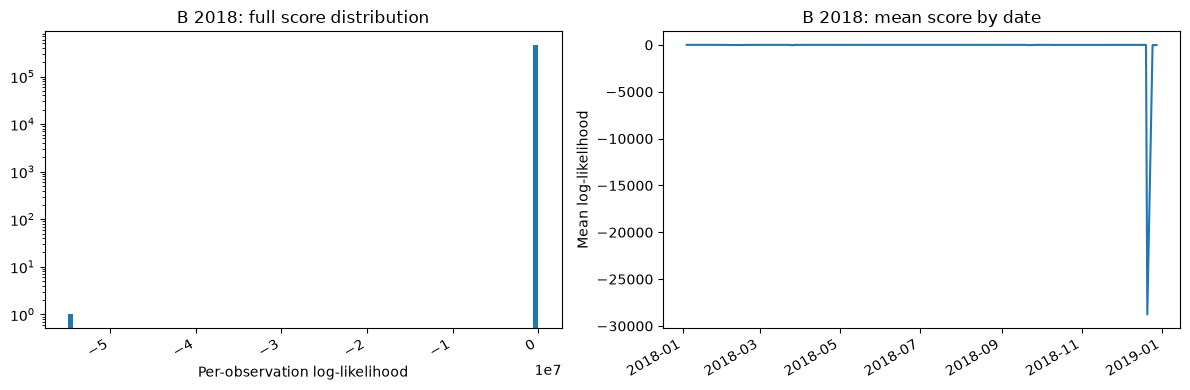

In [ ]:
for grouping_name, report in b_tail["group_reports"].items():
    print("\nGrouping:", grouping_name)
    display(report.head(15))
    report.to_csv(DIAG_OUT / f"B_2018_tail_by_{grouping_name}.csv")

# Compare flag prevalence in training and validation.
for flag in ["HasExpectedDividend", "SupervisionFlag", "AdjustmentEventFlag"]:
    prevalence = pd.concat(
        {
            "training_share": b_training_sample[flag].value_counts(
                normalize=True, dropna=False
            )
            ,"validation_share": b_validation_rows[flag].value_counts(
                normalize=True, dropna=False
            )
        }
        ,axis=1
    ).fillna(0)
    print("\nFlag prevalence:", flag)
    display(prevalence)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(b_scores["log_likelihood"], bins=100)
axes[0].set_title("B 2018: full score distribution")
axes[0].set_xlabel("Per-observation log-likelihood")
axes[0].set_yscale("log")

daily_scores = b_scores.groupby("Date")["log_likelihood"].mean()
axes[1].plot(daily_scores.index, daily_scores.values)
axes[1].set_title("B 2018: mean score by date")
axes[1].set_ylabel("Mean log-likelihood")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(DIAG_OUT / "B_2018_score_diagnostics.png", dpi=150)
plt.show()

The tail table partitions the complete validation year. Its two `contribution_to_full_mean` values sum to the reported full-year mean: this shows whether the worst 0.1% dominates the result. Do **not** delete that tail to improve the official validation score.

A group tail enrichment above one means over-representation in the worst tail; small groups need cautious interpretation. This is association, not a causal attribution to a flag or missingness. The financial missingness indicator records raw missing values, not proof that imputation caused the failure.

Near-floor covariance eigenvalues, high condition numbers, or extreme transformed values motivate closer inspection. None establishes the cause alone. Inspect the actual worst rows and relevant financial/event histories.

## 3. Isolate validation coverage using the same fitted B model

No model or preprocessor is refitted here. The fixed 50000-row sample, its complement and the complete year use cached per-row scores from the exact same model. This isolates evaluation coverage, not training-size effects.

In [ ]:
coverage_comparison, fixed_sample_keys = compare_validation_coverage(
    b_validation_rows
    ,b_scores
    ,sampling_seed=cfg.random_seed + 1
    ,cap=50000
)

tail_audit = b_tail["audit"]
in_fixed_sample = tail_audit.index.isin(fixed_sample_keys)

coverage_comparison["worst_tail_count"] = [
    int(tail_audit["in_worst_tail"].sum())
    ,int(tail_audit.loc[in_fixed_sample, "in_worst_tail"].sum())
    ,int(tail_audit.loc[~in_fixed_sample, "in_worst_tail"].sum())
]

display(coverage_comparison)
coverage_comparison.to_csv(
    DIAG_OUT / "B_2018_validation_coverage.csv"
    ,index=False
)

# Verify that sample and complement reconstruct the full-year mean.
parts = coverage_comparison.loc[
    coverage_comparison["validation_subset"].ne("complete_year")
]
reconstructed_mean = (
    (parts["count"] * parts["mean_ll"]).sum()
    / parts["count"].sum()
)
assert np.isclose(reconstructed_mean, refitted_ll)
print("Weighted sample/complement mean:", reconstructed_mean)

,validation_subset,count,mean_ll,minimum_ll,q001_ll,worst_tail_count
0,complete_year,464576,-112.796318,-5.493108e+07,-109.080075,465
1,fixed_sample,50000,5.182959,-1.148326e+04,-109.499185,51
2,outside_sample,414576,-127.025226,-5.493108e+07,-108.970556,414


Weighted sample/complement mean: -112.79631797560249


If the sample is much better than the full year and tail failures concentrate outside it, limited validation coverage can explain a screening blind spot. If both are poor, the failure is visible even in a 50000-row sample for this fitted model.

To isolate **training size** separately, repeat the same configuration with a 50000-row training cap and score the same full validation year. Do not change training size and validation coverage simultaneously when diagnosing their effects.

## 4. Test one targeted remedy after inspecting the evidence

The shared `src.modeling.fit_gmm()` accepts regularization, initialization and tolerance settings. Remedy CV reuses `run_gmm_cv()` with these overrides; candidate fitting and diagnostics also use the same fitting implementation.

Leave the switch false until diagnosis supports an experiment. The example changes one factor at a time: regularization or the number of restarts. It evaluates all three chronological folds and seeds with the same row budgets and saves after every fit. Three variants require 27 fits. The checkpoint preserves results but does not implement automatic resume.

In [ ]:
RUN_REMEDY_CV = False

remedy_variants = {
    "baseline": {}
    ,"reg_1e_4": {
        "fit_options": {"reg_covar": 1e-4}
    }
    ,"more_restarts": {
        "fit_options": {"n_init": 5}
    }
}

# If event diagnostics justify it, add this as a separate feature specification.
# Do not compare its raw likelihood level directly with the original B space.
# event_features = {
#     "ExpectedDividend", "HasExpectedDividend"
#     ,"SupervisionFlag", "AdjustmentEventFlag"
# }
# remedy_variants["B_without_events"] = {
#     "features": [
#         feature for feature in feature_sets["B"]
#         if feature not in event_features
#     ]
# }

if RUN_REMEDY_CV:
    remedy_cv = run_remedy_cv(
        development_rows
        ,feature_sets["B"]
        ,cfg
        ,reference_fit_options
        ,remedy_variants
        ,model_seeds=(4, 14, 24)
        ,k=5
        ,checkpoint_path=DIAG_OUT / "B_remedy_cv.csv"
    )

    remedy_summary = remedy_cv.groupby(
        "variant"
        ,as_index=False
    ).agg(
        mean_train_ll=("train_ll", "mean")
        ,mean_valid_ll=("valid_ll", "mean")
        ,worst_valid_ll=("valid_ll", "min")
        ,all_converged=("converged", "all")
        ,n_runs=("seed", "size")
        ,n_scored=("valid_ll", "count")
    )

    display(remedy_summary)
    display(
        remedy_cv.groupby(["variant", "fold"])["valid_ll"]
        .agg(["mean", "min", "max"])
    )
    remedy_summary.to_csv(
        DIAG_OUT / "B_remedy_summary.csv"
        ,index=False
    )
else:
    print("Remedy CV is disabled. Inspect B's diagnostic tables first.")

Remedy CV is disabled. Inspect B's diagnostic tables first.


Choose a remedy based on repeatable improvement across years and seeds, completeness of results, and avoidance of catastrophic scores. More restarts or regularization do not guarantee better validation performance.

For feature ablations or changed scaling, likelihood describes a different feature space or coordinate system. Compare failure frequency, stability and interpretation; do not select a feature specification by its raw likelihood level. If adopting a revised feature set, version its list and update downstream provenance rather than silently modifying frozen B.

A custom `preprocessor_factory` can be supplied in a variant; it is freshly fitted using training rows only in each fold.

## 5. Refit and save updated candidates with an explicit budget

After reviewing Step 1's profiles/stability, this cell refits the three provisional candidates with five restarts. It uses training rows through 2019 so 2020 remains later data for these fitted candidates. The anchor metrics are explicitly labelled as development-anchor diagnostics.

B is excluded until its failure is resolved. These fits update candidates, **not** the final locked model. The explicit cap prevents an accidental return to the quick profile's 50000 rows.

In [ ]:
updated_fit_options = {
    "train_cap": 200000
    ,"n_init": 5
    ,"max_iter": 300
    ,"reg_covar": 1e-5
    ,"tol": 1e-3
    ,"init_params": "kmeans"
}

updated_artifacts = fit_candidates(
    training_rows
    ,feature_sets
    ,None
    ,cfg
    ,specifications=provisional_specifications
    ,fit_options=updated_fit_options
    ,model_seed=24
    ,compute_metrics=False
    ,require_convergence=False
)[0]

candidate_records = []
updated_scores = {}

for candidate_id, artifact in updated_artifacts.items():
    if not artifact["converged"]:
        raise ValueError(f"{candidate_id} did not converge.")

    scores = predict_states(
        artifact
        ,anchor_rows
        ,cfg
        ,include_diagnostics=True
    )
    updated_scores[candidate_id] = scores
    profiles = describe_assignments(
        artifact, anchor_rows, scores, cfg
    )
    scaled_anchor = artifact["preprocessor"].transform(
        anchor_rows[artifact["features"]]
    )

    matched_cv = confirmation_summary.loc[
        confirmation_summary["feature_set"].eq(artifact["feature_set"])
        & confirmation_summary["k"].eq(artifact["model"].n_components)
        & confirmation_summary["covariance"].eq(
            artifact["model"].covariance_type
        )
    ]
    if len(matched_cv) != 1:
        raise ValueError(f"Missing unique confirmation summary for {candidate_id}.")

    confirmation_row = matched_cv.iloc[0]
    expected_runs = (
        pd.Timestamp(cfg.development_end).year
        - pd.Timestamp(cfg.feature_selection_end).year
    ) * len(confirmation_settings["options"]["random_seeds"])
    if (
        str(confirmation_row["all_converged"]).lower() != "true"
        or int(confirmation_row["n_runs"]) != expected_runs
        or int(confirmation_row["n_scored"]) != expected_runs
    ):
        raise ValueError(f"Incomplete or non-converged confirmation for {candidate_id}.")

    candidate_records.append({
        "candidate_id": candidate_id
        ,"feature_set": artifact["feature_set"]
        ,"n_features": len(artifact["features"])
        ,"k": artifact["model"].n_components
        ,"covariance": artifact["model"].covariance_type
        ,"cv_ll_within_set": float(matched_cv.iloc[0]["mean_valid_ll"])
        ,"n_train": artifact["n_train"]
        ,"n_anchor": len(anchor_rows)
        ,"metrics_period": "2020_development_anchor"
        ,"mean_anchor_max_probability": scores["StateProbability"].mean()
        ,"mean_anchor_normalized_entropy": scores["normalized_entropy"].mean()
        ,**cluster_metrics(
            scaled_anchor
            ,scores["State"].to_numpy()
            ,random_seed=cfg.random_seed
        )
    })

    scores.to_csv(DIAG_OUT / f"updated_{candidate_id}_anchor_assignments.csv")
    for table_name, table in profiles.items():
        table.to_csv(DIAG_OUT / f"updated_{candidate_id}_{table_name}.csv")

updated_candidates = pd.DataFrame(candidate_records)
updated_directory = DIAG_OUT / "updated_candidates"

updated_ids = save_candidate_bundle(
    updated_artifacts
    ,updated_candidates
    ,updated_directory
)

# These variables can be used by subsequent cells in this notebook.
artifacts = updated_artifacts
candidates = updated_candidates
ids = updated_ids

display(candidates)
print("Updated candidate bundle:", updated_directory)

KeyboardInterrupt: 

Changing n_init changes the fitting procedure: inspect the updated profiles and, before accepting the updated models, repeat assignment stability with the same five-restart budget. This is more expensive than the two-restart reference checks and should be run after Step 5.

In [ ]:
RUN_UPDATED_STABILITY = False

if RUN_UPDATED_STABILITY:
    updated_stability = assignment_stability(
        training_rows
        ,anchor_rows
        ,feature_sets
        ,provisional_specifications
        ,updated_artifacts
        ,cfg
        ,updated_fit_options
        ,model_seeds=(4, 14)
        ,sampling_seeds=(142, 242)
    )
    updated_stability.to_csv(
        DIAG_OUT / "updated_assignment_stability.csv"
        ,index=False
    )
    display(updated_stability)